In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_epochs = 10
batch_size = 64
learning_rate = 0.01

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

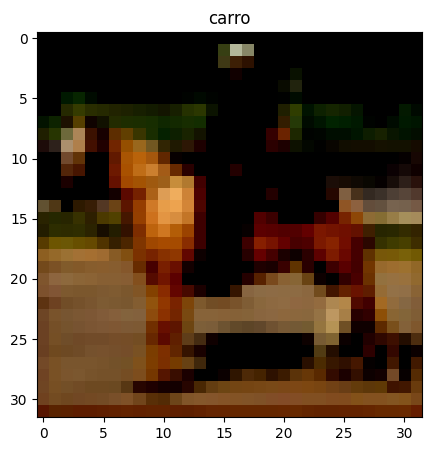

In [20]:
import matplotlib.pyplot as plt
import numpy as np

classes = ['avião', 'carro', 'pássaro', 'gato', 'corvo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão']

imagens, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))
plt.imshow(np.transpose(images.numpy()[0], (1, 2, 0)))
plt.title(classes[labels[0].item()])
plt.show()

In [3]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

model = ConvNet().to(device)

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(f'Época {epoch+1}: loss = {running_loss / len(train_loader):.3f}')

Época 1: loss = 1.840
Época 2: loss = 1.404
Época 3: loss = 1.247
Época 4: loss = 1.132
Época 5: loss = 1.053
Época 6: loss = 0.988
Época 7: loss = 0.938
Época 8: loss = 0.889
Época 9: loss = 0.849
Época 10: loss = 0.813


In [11]:
classes = ('avião', 'carro', 'pássaro', 'gato', 'cervo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhão')

model.eval()
correct, total = 0, 0
class_correct, class_total = [0] * 10, [0] * 10

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        for l, p in zip(labels.tolist(), predicted.tolist()):
            class_total[l] += 1
            class_correct[l] += int(l == p)

print(f'Acurácia geral: {100 * correct / total:.1f}%')
for i in range(10):
    print(f'{classes[i]:9}: {100 * class_correct[i] / class_total[i]:.1f}%')

Acurácia geral: 62.1%
avião    : 81.5%
carro    : 71.6%
pássaro  : 47.5%
gato     : 40.8%
cervo    : 57.4%
cachorro : 50.0%
sapo     : 71.7%
cavalo   : 68.7%
navio    : 54.5%
caminhão : 77.3%


Saving aviao1.jpg to aviao1 (3).jpg


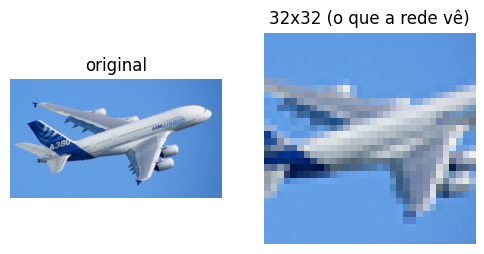

avião     : 97.5%
navio     : 2.5%
carro     : 0.0%


In [19]:
from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
nome = list(uploaded.keys())[0]

img = Image.open(nome).convert('RGB')
img_32 = ImageOps.fit(img, (32, 32), method=Image.LANCZOS)

x = transform(img_32).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
  probs = F.softmax(model(x), dim=1)[0]

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(img);  axes[0].set_title('original');  axes[0].axis('off')
axes[1].imshow(img_32);  axes[1].set_title('32x32 (o que a rede vê)');  axes[1].axis('off')
plt.show()

top = torch.topk(probs, 3)
for p, i in zip(top.values, top.indices):
  print(f'{classes[i]:10}: {p*100:.1f}%')